# Detecção de fraude em cartões de crédito
**Giordani Martins Silva · Projeto educacional DIO**

Da base real à decisão explicada: regressão logística, Random Forest e XGBoost.

## Pergunta e protocolo
Queremos encontrar fraudes sem gerar uma fila ilimitada de falsos alarmes. **Recall da fraude é a prioridade**, com precisão mínima de **80% na validação**, uma hipótese didática, não uma política bancária. Se um modelo não atingir esse piso, mostramos sua melhor alternativa por F1, mas ele não é elegível como vencedor.

O teste fica intocado até congelarmos o modelo e os limiares. Comparamos pesos de classe e reamostragem somente no treino. Uma previsão não determina culpa: o projeto não é um sistema de produção.

## Fonte
Base Credit Card Fraud Detection (ULB/Worldline), distribuída também pelo [tutorial oficial do TensorFlow](https://www.tensorflow.org/tutorials/structured_data/imbalanced_data). O link da Aula 1 não foi fornecido; usamos esse espelho público documentado da base com o mesmo esquema. Não afirmamos que esta é a URL exata usada pela professora. O CSV não acompanha o repositório.

As variáveis V1–V28 já são componentes PCA: seus significados originais não estão disponíveis. Não refazemos o PCA nem inventamos interpretações como localização ou renda.


In [1]:
# Se necessário, execute antes em um ambiente limpo:
# %pip install -r ../requirements.txt
import os, sys, json, hashlib, platform, time
from pathlib import Path
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (precision_recall_curve, roc_curve, roc_auc_score,
    average_precision_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler
from xgboost import XGBClassifier
import shap
SEED = 42
MIN_PRECISION = 0.80
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
OUT = ROOT / 'results'
OUT.mkdir(exist_ok=True, parents=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
packages = ['numpy','pandas','scikit-learn','imbalanced-learn','xgboost','shap','matplotlib','nbformat','nbclient','ipykernel']
versions = {name: version(name) for name in packages}
print('Python:', platform.python_version())
display(pd.Series(versions, name='versão'))
(OUT / 'versions.json').write_text(json.dumps(versions, indent=2))


Python: 3.12.14
Out[0]: 242


numpy                2.3.5
pandas               2.2.3
scikit-learn         1.8.0
imbalanced-learn    0.14.2
xgboost              3.4.1
shap                0.53.0
matplotlib          3.10.8
nbformat            5.11.1
nbclient            0.11.0
ipykernel            7.4.0
Name: versão, dtype: object

## 1. Exploração e integridade
Baixamos por URL por padrão. `CREDITCARD_PATH` é um cache local opcional para evitar novo download durante a execução; não altera os dados. Verificamos esquema, valores ausentes e duplicatas exatas. Removemos duplicatas antes da separação, de modo que uma linha idêntica não apareça no treino e no teste. Essa decisão altera a prevalência em relação à base bruta e é registrada abaixo.


Base bruta: 284,807 linhas; 492 fraudes; 0.1727% fraudes.
Duplicatas exatas: 1081
Após deduplicação: 283,726 linhas; 473 fraudes; 0.1667% fraudes.


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


,Time,Amount
count,283726.000000,283726.000000
mean,94811.077600,88.472687
std,47481.047891,250.399437
min,0.000000,0.000000
25%,54204.750000,5.600000
50%,84692.500000,22.000000
75%,139298.000000,77.510000
max,172792.000000,25691.160000


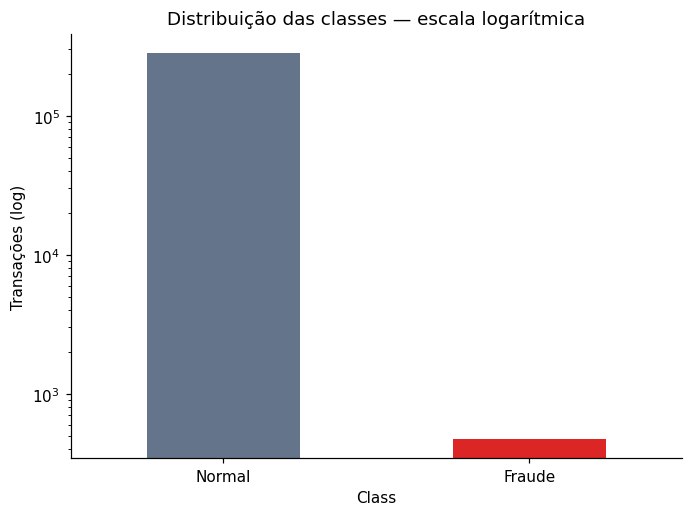

In [2]:
DATA_URL = 'https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv'
source = os.environ.get('CREDITCARD_PATH', DATA_URL)
raw = pd.read_csv(source)
expected = ['Time'] + [f'V{i}' for i in range(1,29)] + ['Amount','Class']
assert list(raw.columns) == expected, 'Esquema inesperado'
assert not raw.isna().any().any(), 'Investigue valores ausentes antes de continuar'
assert set(raw['Class'].unique()) == {0,1}
assert (raw['Amount'] >= 0).all()
assert np.isfinite(raw.to_numpy()).all()
print(f'Base bruta: {len(raw):,} linhas; {raw.Class.sum()} fraudes; {raw.Class.mean():.4%} fraudes.')
print('Duplicatas exatas:', raw.duplicated().sum())
df = raw.drop_duplicates().reset_index(drop=True)
print(f'Após deduplicação: {len(df):,} linhas; {df.Class.sum()} fraudes; {df.Class.mean():.4%} fraudes.')
display(df.head())
display(df[['Time','Amount']].describe())
counts = df.Class.value_counts().rename(index={0:'Normal',1:'Fraude'})
ax = counts.plot.bar(color=['#64748b','#dc2626'], rot=0, title='Distribuição das classes — escala logarítmica', logy=True)
ax.set_ylabel('Transações (log)')
plt.tight_layout(); plt.savefig(OUT/'classes.png'); plt.show()


## 2. Preparação sem vazamento
Criamos `LogAmount = log1p(Amount)` e `ElapsedHours = Time/3600`. Não chamamos isso de “hora do dia”: o horário de início não é conhecido. Mantemos `Amount` e V1–V28 e retiramos `Time` após a conversão.

A separação é estratificada em aproximadamente **60% treino / 20% validação / 20% teste**. `StandardScaler` é ajustado apenas no treino, dentro dos pipelines logísticos; árvores não precisam de padronização. Sem identificador de cliente/cartão, não criamos supostas sequências por pessoa. A separação aleatória é uma avaliação didática, não uma simulação de previsão de fraudes futuras.


In [3]:
X = df.drop(columns='Class').copy()
X['LogAmount'] = np.log1p(X['Amount'])
X['ElapsedHours'] = X.pop('Time') / 3600
y = df['Class'].astype(int)
X_dev, X_test, y_dev, y_test = train_test_split(X,y,test_size=0.20,stratify=y,random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_dev,y_dev,test_size=0.25,stratify=y_dev,random_state=SEED)
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)
splits = pd.DataFrame([{'conjunto':name,'linhas':len(labels),'fraudes':int(labels.sum()),'proporcao_fraude':labels.mean()}
    for name,labels in [('treino',y_train),('validacao',y_val),('teste',y_test)]])
display(splits)
splits.to_csv(OUT/'splits.csv',index=False)


,conjunto,linhas,fraudes,proporcao_fraude
0,treino,170235,284,0.001668
1,validacao,56745,94,0.001657
2,teste,56746,95,0.001674


## 3. Modelos e desbalanceamento
- Baseline ingênuo: sempre normal, para demonstrar o problema da acurácia.
- Regressão logística com pesos balanceados.
- Random Forest com pesos por amostra bootstrap.
- XGBoost com `scale_pos_weight` calculado **somente no treino**.
- Regressão logística com undersampling e com oversampling aleatórios (razão minoria/maioria de 0,1).

Reamostramos somente o treino dentro dos pipelines. As duas alternativas de amostragem não acumulam pesos balanceados, para permitir uma comparação mais clara. Hiperparâmetros foram fixados previamente para uma execução acessível em CPU; não foi executado GridSearchCV. Os modelos produzem escores, não probabilidades calibradas de risco.


In [4]:
def logistic(weight=None):
    return LogisticRegression(class_weight=weight,max_iter=1500,random_state=SEED)
ratio = int((y_train==0).sum()) / int((y_train==1).sum())
models = {
 'Logistica_pesos': make_pipeline(StandardScaler(),logistic('balanced')),
 'RandomForest_pesos': RandomForestClassifier(n_estimators=120,max_depth=14,min_samples_leaf=2,class_weight='balanced_subsample',n_jobs=2,random_state=SEED),
 'XGBoost_pesos': XGBClassifier(n_estimators=220,max_depth=4,learning_rate=0.06,subsample=0.85,colsample_bytree=0.85,scale_pos_weight=ratio,tree_method='hist',eval_metric='logloss',n_jobs=2,random_state=SEED),
 'Logistica_under': ImbPipeline([('scale',StandardScaler()),('sampling',RandomUnderSampler(sampling_strategy=0.1,random_state=SEED)),('model',logistic())]),
 'Logistica_over': ImbPipeline([('scale',StandardScaler()),('sampling',RandomOverSampler(sampling_strategy=0.1,random_state=SEED)),('model',logistic())])
}
val_scores, fit_seconds = {}, {}
for name, model in models.items():
    start=time.perf_counter()
    model.fit(X_train,y_train)
    fit_seconds[name]=time.perf_counter()-start
    val_scores[name]=model.predict_proba(X_val)[:,1]
    print(f'{name}: treino em {fit_seconds[name]:.1f}s',flush=True)


Logistica_pesos: treino em 0.5s
RandomForest_pesos: treino em 46.4s
XGBoost_pesos: treino em 3.0s
Logistica_under: treino em 0.1s
Logistica_over: treino em 0.4s


## 4. Escolha do limiar e do modelo na validação
Em cada modelo, maximizamos o recall entre os limiares com precisão ≥ 80%. Desempates favorecem precisão e depois limiar maior. Se a restrição não for atendida, usamos o melhor F1 apenas como alternativa descritiva. O campeão é escolhido **na validação**, entre modelos elegíveis, por recall e depois precisão. Nenhuma decisão usa os resultados do teste.


Modelo selecionado antes de abrir o teste: XGBoost_pesos


,model,eligible,threshold,precision,recall,f1,average_precision,roc_auc,accuracy,tp,fp,fn,tn
0,Logistica_pesos,True,1.00000,0.85714,0.82979,0.84324,0.78806,0.97923,0.99949,78,13,16,56638
1,RandomForest_pesos,True,0.34129,0.85263,0.86170,0.85714,0.86780,0.95185,0.99952,81,14,13,56637
2,XGBoost_pesos,True,0.69109,0.82828,0.87234,0.84974,0.87444,0.97334,0.99949,82,17,12,56634
3,Logistica_under,True,0.99950,0.81944,0.62766,0.71084,0.73630,0.97927,0.99915,59,13,35,56638
4,Logistica_over,True,0.99364,0.80220,0.77660,0.78919,0.79967,0.97958,0.99931,73,18,21,56633


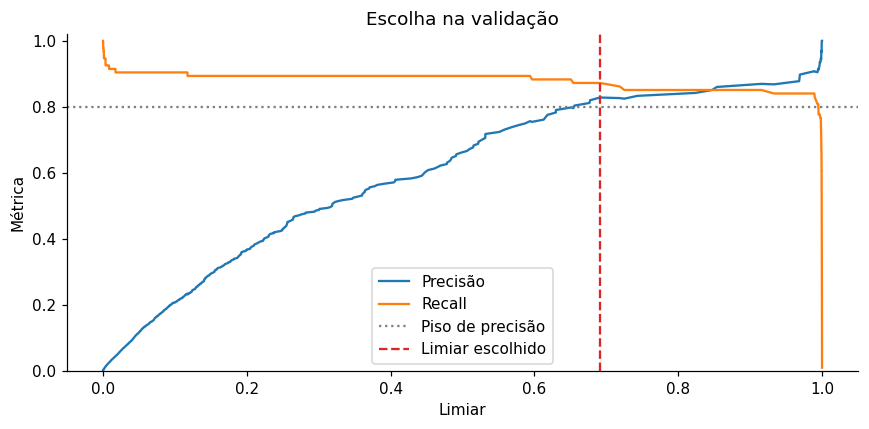

In [5]:
def select_threshold(labels, scores):
    p,r,t = precision_recall_curve(labels,scores)
    table = pd.DataFrame({'threshold':t,'precision':p[:-1],'recall':r[:-1]})
    table['f1']=2*table.precision*table.recall/(table.precision+table.recall).clip(lower=1e-15)
    feasible=table[table.precision >= MIN_PRECISION]
    eligible=not feasible.empty
    if eligible:
        row=feasible.sort_values(['recall','precision','threshold'],ascending=False).iloc[0]
    else:
        row=table.sort_values(['f1','recall','precision'],ascending=False).iloc[0]
    return float(row.threshold), eligible

def metrics(labels,scores,threshold):
    pred=(scores>=threshold).astype(int)
    tn,fp,fn,tp=confusion_matrix(labels,pred,labels=[0,1]).ravel()
    return {'threshold':threshold,'precision':precision_score(labels,pred,zero_division=0),
        'recall':recall_score(labels,pred),'f1':f1_score(labels,pred,zero_division=0),
        'average_precision':average_precision_score(labels,scores),'roc_auc':roc_auc_score(labels,scores),
        'accuracy':accuracy_score(labels,pred),'tp':int(tp),'fp':int(fp),'fn':int(fn),'tn':int(tn)}
thresholds, val_rows = {}, []
for name,scores in val_scores.items():
    threshold,eligible=select_threshold(y_val,scores)
    thresholds[name]=threshold
    val_rows.append({'model':name,'eligible':eligible,**metrics(y_val,scores,threshold)})
validation=pd.DataFrame(val_rows)
feasible=validation[validation.eligible]
assert not feasible.empty, 'Nenhum modelo atendeu à regra; revise o objetivo usando apenas a validação.'
champion=feasible.sort_values(['recall','precision','f1'],ascending=False).iloc[0]['model']
print('Modelo selecionado antes de abrir o teste:',champion)
display(validation.round(5))
validation.to_csv(OUT/'validation_metrics.csv',index=False)
fig,ax=plt.subplots(figsize=(8,4))
p,r,t=precision_recall_curve(y_val,val_scores[champion])
ax.plot(t,p[:-1],label='Precisão'); ax.plot(t,r[:-1],label='Recall')
ax.axhline(MIN_PRECISION,color='grey',ls=':',label='Piso de precisão')
ax.axvline(thresholds[champion],color='#dc2626',ls='--',label='Limiar escolhido')
ax.set(xlabel='Limiar',ylabel='Métrica',title='Escolha na validação',ylim=(0,1.02)); ax.legend()
plt.tight_layout(); plt.savefig(OUT/'threshold_validation.png'); plt.show()


## 5. Avaliação final no teste reservado
Recall = fraudes encontradas / todas as fraudes. Precisão = fraudes reais / todos os alertas. F1 combina os dois. AP (average precision) resume a curva precisão–recall; **não é a mesma definição que a área trapezoidal**. ROC-AUC é complementar. A precisão mínima na validação não garante o mesmo valor no teste.

Avaliamos o limiar padrão 0,5 e o limiar congelado de cada modelo. O campeão não será trocado após observar esta tabela.


Sempre normal — acurácia: 99.8326%; recall: 0.0%

Logistica_pesos — limiar ajustado
              precision    recall  f1-score   support

      Normal     0.9996    0.9998    0.9997     56651
      Fraude     0.8391    0.7684    0.8022        95

    accuracy                         0.9994     56746
   macro avg     0.9193    0.8841    0.9009     56746
weighted avg     0.9993    0.9994    0.9994     56746


RandomForest_pesos — limiar ajustado
              precision    recall  f1-score   support

      Normal     0.9996    0.9999    0.9997     56651
      Fraude     0.9012    0.7684    0.8295        95

    accuracy                         0.9995     56746
   macro avg     0.9504    0.8841    0.9146     56746
weighted avg     0.9994    0.9995    0.9995     56746


XGBoost_pesos — limiar ajustado
              precision    recall  f1-score   support

      Normal     0.9997    0.9996    0.9996     56651
      Fraude     0.7700    0.8105    0.7897        95

    accuracy               

,model,rule,threshold,precision,recall,f1,average_precision,roc_auc,accuracy,tp,fp,fn,tn
0,Logistica_pesos,padrao_0.5,0.50000,0.05080,0.87368,0.09601,0.68846,0.96397,0.97246,83,1551,12,55100
1,Logistica_pesos,ajustado_validacao,1.00000,0.83908,0.76842,0.80220,0.68846,0.96397,0.99937,73,14,22,56637
2,RandomForest_pesos,padrao_0.5,0.50000,0.94444,0.71579,0.81437,0.80959,0.94426,0.99945,68,4,27,56647
3,RandomForest_pesos,ajustado_validacao,0.34129,0.90123,0.76842,0.82955,0.80959,0.94426,0.99947,73,8,22,56643
4,XGBoost_pesos,padrao_0.5,0.50000,0.67544,0.81053,0.73684,0.81186,0.96754,0.99903,77,37,18,56614
5,XGBoost_pesos,ajustado_validacao,0.69109,0.77000,0.81053,0.78974,0.81186,0.96754,0.99928,77,23,18,56628
6,Logistica_under,padrao_0.5,0.50000,0.25246,0.81053,0.38500,0.54083,0.96003,0.99566,77,228,18,56423
7,Logistica_under,ajustado_validacao,0.99950,0.67568,0.52632,0.59172,0.54083,0.96003,0.99878,50,24,45,56627
8,Logistica_over,padrao_0.5,0.50000,0.42541,0.81053,0.55797,0.69729,0.96062,0.99785,77,104,18,56547
9,Logistica_over,ajustado_validacao,0.99364,0.81928,0.71579,0.76404,0.69729,0.96062,0.99926,68,15,27,56636


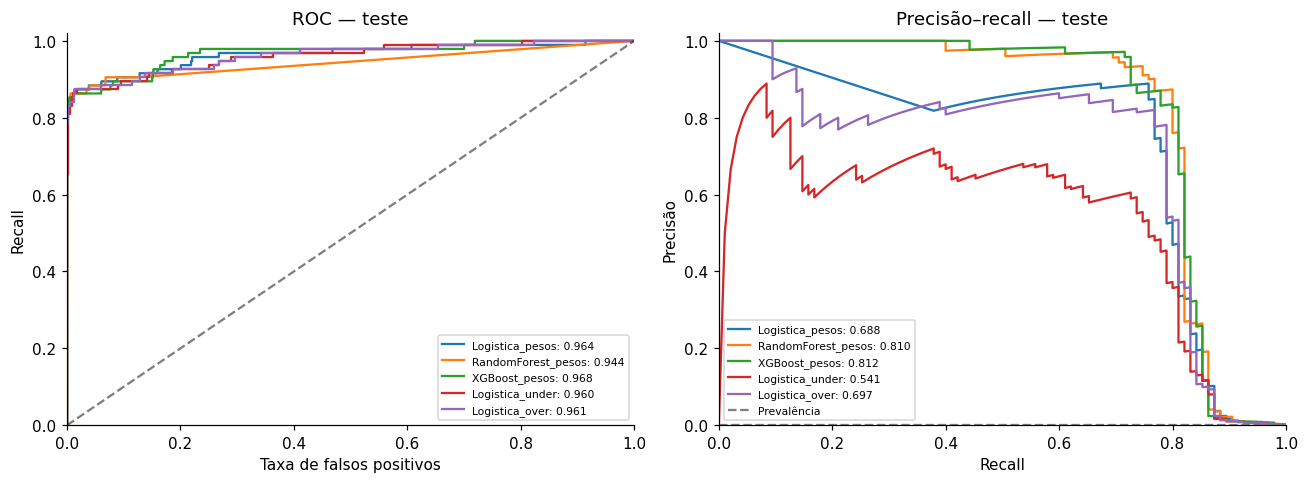

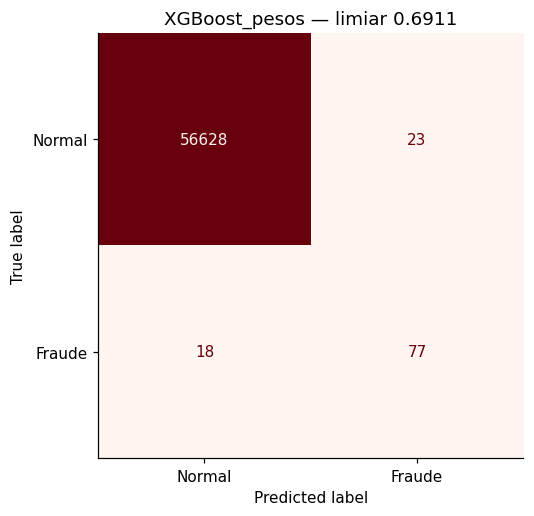

In [6]:
test_scores={name:model.predict_proba(X_test)[:,1] for name,model in models.items()}
rows=[]
for name,scores in test_scores.items():
    for rule,threshold in [('padrao_0.5',0.5),('ajustado_validacao',thresholds[name])]:
        rows.append({'model':name,'rule':rule,**metrics(y_test,scores,threshold)})
test_table=pd.DataFrame(rows)
display(test_table.round(5))
test_table.to_csv(OUT/'test_metrics.csv',index=False)
dummy=DummyClassifier(strategy='most_frequent').fit(X_train,y_train)
dummy_pred=dummy.predict(X_test)
print(f'Sempre normal — acurácia: {accuracy_score(y_test,dummy_pred):.4%}; recall: {recall_score(y_test,dummy_pred):.1%}')
reports={}
for name,scores in test_scores.items():
    report=classification_report(y_test,(scores>=thresholds[name]).astype(int),target_names=['Normal','Fraude'],digits=4,zero_division=0)
    reports[name]=report
    print('\n'+name+' — limiar ajustado\n'+report)
(OUT/'classification_reports.txt').write_text('\n\n'.join(k+'\n'+v for k,v in reports.items()))
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for name,scores in test_scores.items():
    fpr,tpr,_=roc_curve(y_test,scores); p,r,_=precision_recall_curve(y_test,scores)
    axes[0].plot(fpr,tpr,label=f'{name}: {roc_auc_score(y_test,scores):.3f}')
    axes[1].plot(r,p,label=f'{name}: {average_precision_score(y_test,scores):.3f}')
axes[0].plot([0,1],[0,1],'k--',alpha=.5)
axes[0].set(xlabel='Taxa de falsos positivos',ylabel='Recall',title='ROC — teste')
axes[1].axhline(y_test.mean(),ls='--',color='grey',label='Prevalência')
axes[1].set(xlabel='Recall',ylabel='Precisão',title='Precisão–recall — teste')
for ax in axes: ax.legend(fontsize=7); ax.set_xlim(0,1); ax.set_ylim(0,1.02)
plt.tight_layout(); plt.savefig(OUT/'curves_test.png'); plt.show()
selected_pred=(test_scores[champion]>=thresholds[champion]).astype(int)
ConfusionMatrixDisplay.from_predictions(y_test,selected_pred,display_labels=['Normal','Fraude'],cmap='Reds',colorbar=False)
plt.title(f'{champion} — limiar {thresholds[champion]:.4f}')
plt.tight_layout(); plt.savefig(OUT/'confusion_test.png'); plt.show()


## 6. Explicabilidade: importância e SHAP
Explicamos o XGBoost, identificado pelo nome, independentemente de ser ou não campeão. Sua importância interna é baseada em ganho; comparamos com a média do valor absoluto de SHAP em uma amostra aleatória de 500 transações do teste. Essa pequena amostra global contém sobretudo operações normais e não representa todas as fraudes.

O waterfall usa a primeira transação, na ordem fixa do teste, que o XGBoost marcou como fraude. A seleção usa a previsão, não o rótulo real; depois mostramos se acertou. SHAP explica o **escore do modelo em log-odds**, não causa da fraude. Contribuição positiva aumenta o escore. Por causa do PCA não podemos atribuir significados originais a V1–V28.


Índice da transação deduplicada: 115676; rótulo real: 1; escore: 0.999547; limiar XGBoost: 0.691087


V14       0.346360
V10       0.085548
V4        0.063321
V8        0.048127
V20       0.038538
V12       0.037011
V19       0.032225
Amount    0.030914
V13       0.028304
V22       0.023802
Name: importancia_gain, dtype: float32

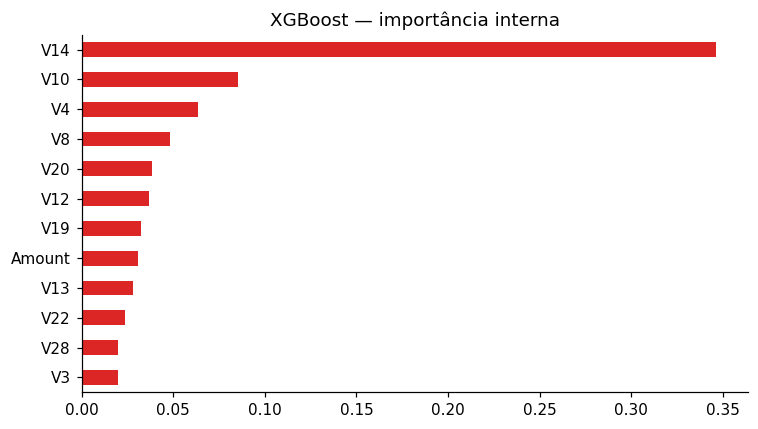

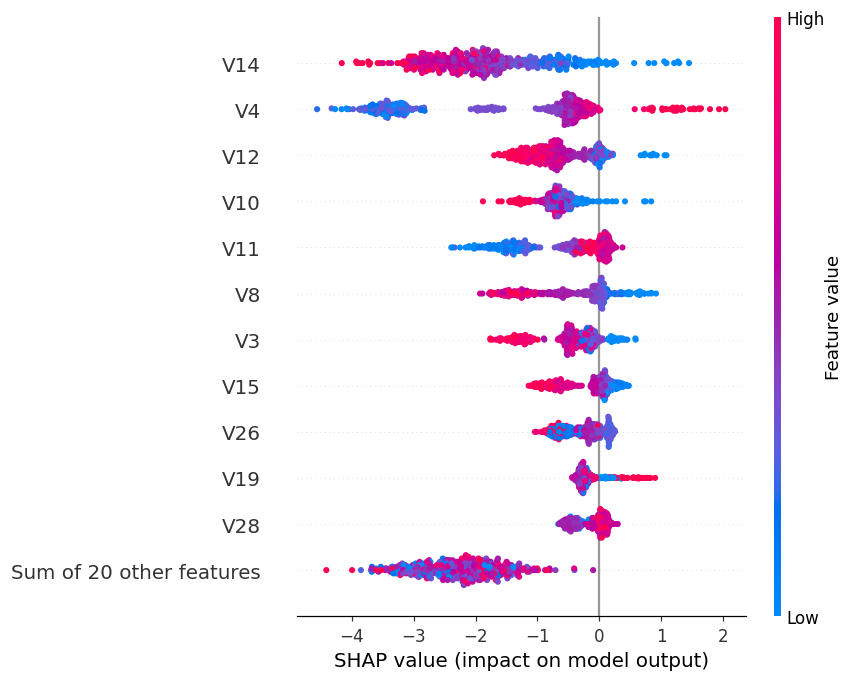

,feature,value,shap_log_odds,abs_shap
13,V14,-3.822894,3.358356,3.358356
9,V10,-3.538650,1.665994,1.665994
11,V12,-3.993373,1.187814,1.187814
3,V4,2.213085,0.781426,0.781426
7,V8,1.197169,-0.760369,0.760369
15,V16,-2.475359,0.490079,0.490079
6,V7,-2.356013,0.426800,0.426800
10,V11,3.102090,0.273596,0.273596
1,V2,1.808698,-0.263310,0.263310
28,Amount,76.940000,-0.230380,0.230380


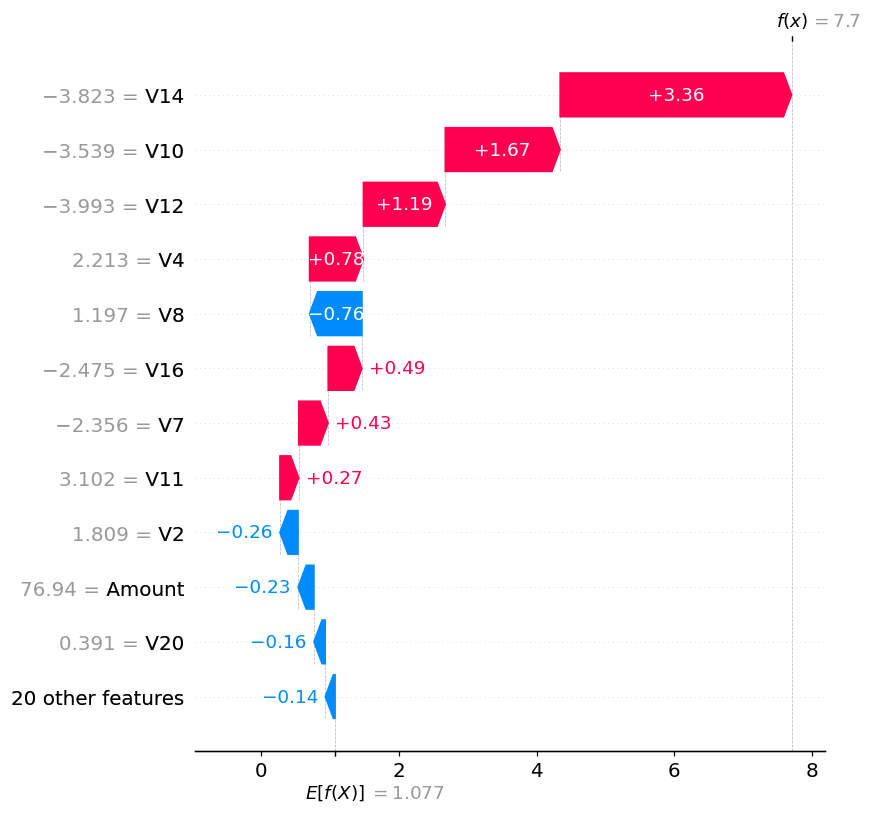

In [7]:
xgb=models['XGBoost_pesos']
importance=pd.Series(xgb.feature_importances_,index=X.columns).sort_values(ascending=False)
display(importance.head(10).rename('importancia_gain'))
importance.head(12).sort_values().plot.barh(figsize=(7,4),color='#dc2626',title='XGBoost — importância interna')
plt.tight_layout(); plt.savefig(OUT/'feature_importance.png'); plt.show()
explainer=shap.TreeExplainer(xgb,model_output='raw',feature_perturbation='tree_path_dependent')
X_explain=X_test.sample(n=min(500,len(X_test)),random_state=SEED)
sv=explainer(X_explain)
shap.plots.beeswarm(sv,max_display=12,show=False)
plt.tight_layout(); plt.savefig(OUT/'shap_global.png',bbox_inches='tight'); plt.show()
global_importance=pd.Series(np.abs(sv.values).mean(axis=0),index=X.columns).sort_values(ascending=False)
global_importance.rename('mean_abs_shap').to_csv(OUT/'shap_global_importance.csv')
flagged=np.flatnonzero(test_scores['XGBoost_pesos']>=thresholds['XGBoost_pesos'])
assert len(flagged)>0, 'XGBoost não gerou alertas no teste'
pos=int(flagged[0])
transaction=X_test.iloc[[pos]]
local=explainer(transaction)
score=float(test_scores['XGBoost_pesos'][pos])
log_odds=float(local.base_values[0]+local.values[0].sum())
assert np.isclose(1/(1+np.exp(-log_odds)),score,atol=1e-5), 'Falha na soma SHAP'
local_table=pd.DataFrame({'feature':X.columns,'value':transaction.iloc[0].values,'shap_log_odds':local.values[0]})
local_table['abs_shap']=local_table.shap_log_odds.abs()
local_table=local_table.sort_values('abs_shap',ascending=False)
local_table.to_csv(OUT/'shap_local.csv',index=False)
print(f'Índice da transação deduplicada: {transaction.index[0]}; rótulo real: {y_test.iloc[pos]}; escore: {score:.6f}; limiar XGBoost: {thresholds["XGBoost_pesos"]:.6f}')
display(local_table.head(10))
shap.plots.waterfall(local[0],max_display=12,show=False)
plt.tight_layout(); plt.savefig(OUT/'shap_local.png',bbox_inches='tight'); plt.show()


## 7. Conclusões e limites
A célula abaixo registra conclusões derivadas da execução, sem números inventados. Seleção por uma única validação tem variância; repetição com sementes diferentes ou validação cruzada aninhada e avaliação temporal são próximos passos. Não foi feita calibração nem estimativa de custos financeiros.

**O que foi acrescentado ao roteiro do enunciado:** validação separada para limiar e escolha de modelo, deduplicação documentada, baseline ingênuo, comparação controlada de pesos/under/over, contagens de falsos positivos e negativos e verificação da soma SHAP. Não tivemos acesso ao notebook da professora para uma comparação linha a linha. Não usamos dados sintéticos como substitutos da base real.


In [8]:
best=test_table[(test_table.model==champion)&(test_table.rule=='ajustado_validacao')].iloc[0]
positive=local_table[local_table.shap_log_odds>0].head(3)
negative=local_table[local_table.shap_log_odds<0].head(3)
summary={'source_url':DATA_URL,'raw_rows':len(raw),'raw_frauds':int(raw.Class.sum()),'duplicates_removed':int(raw.duplicated().sum()),'rows':len(df),'frauds':int(y.sum()),'champion':champion,'threshold':thresholds[champion],
 'test_metrics':best.to_dict(),'shap_model':'XGBoost_pesos','shap_global_top5':global_importance.head(5).to_dict(),
 'shap_local':{'index':int(transaction.index[0]),'label':int(y_test.iloc[pos]),'score':score,'threshold':thresholds['XGBoost_pesos'],'base_log_odds':float(local.base_values[0]),'sum_log_odds':log_odds,'positive_top3':positive.set_index('feature').shap_log_odds.to_dict(),'negative_top3':negative.set_index('feature').shap_log_odds.to_dict()},'seed':SEED}
(OUT/'summary.json').write_text(json.dumps(summary,indent=2,ensure_ascii=False))
print(f'Modelo escolhido na validação: {champion}. Limiar: {thresholds[champion]:.6f}.')
print(f'Teste: recall {best.recall:.2%}, precisão {best.precision:.2%}, F1 {best.f1:.4f}.')
print(f'Fraudes encontradas: {int(best.tp)}; perdidas: {int(best.fn)}; falsos alarmes: {int(best.fp)}.')
print('Maiores contribuições globais SHAP:', ', '.join(global_importance.head(5).index))
print('No alerta explicado, aumentaram o escore:', ', '.join(positive.feature))
print('No alerta explicado, reduziram o escore:', ', '.join(negative.feature))


Modelo escolhido na validação: XGBoost_pesos. Limiar: 0.691087.
Teste: recall 81.05%, precisão 77.00%, F1 0.7897.
Fraudes encontradas: 77; perdidas: 18; falsos alarmes: 23.
Maiores contribuições globais SHAP: V14, V4, V12, V10, V11
No alerta explicado, aumentaram o escore: V14, V10, V12
No alerta explicado, reduziram o escore: V8, V2, Amount


## Referências
- [Base original ULB no Kaggle](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud)
- [Fonte do espelho público — TensorFlow](https://www.tensorflow.org/tutorials/structured_data/imbalanced_data)
- [Escolha do limiar — scikit-learn](https://scikit-learn.org/stable/modules/classification_threshold.html)
- [TreeExplainer — SHAP](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html)
- [Parâmetros — XGBoost](https://xgboost.readthedocs.io/en/stable/parameter.html)
